# Cosmic Motion AI: real SPHEREx data-path feasibility

## tl;dr
**A real repeat pair is available for backend development.** M101 observations on
17 May and 22 June 2026 pass `engineering-preflight-v1`: 353/400 reference pixels
remain jointly usable, and the minimum local FWHM-interval overlap proxy is 98.92%.
A nearby same-detector exposure fails the wavelength gates and common usable coverage.
This demonstrates acquisition and input comparability, not a detected moving object.

## Context & Methods
Diagnostic companion for the backend developer and ML researcher, captured 26 October 2026.
IRSA SIA supplies observation metadata; IBE supplies three real 2-arcmin cutouts at
ICRS (210.80227°, 54.34895°). The manifest pins URLs, source IDs, bytes and SHA-256.
See [research note](README.md), [source manifest](data_path_manifest.json) and
[official cutout tutorial](https://caltech-ipac.github.io/irsa-tutorials/spherex-cutouts/).

### Key Assumptions
- The bounded QR2 query overflowed: the sample proves existence, not survey completeness.
- QR2, processing family l2b-v25, pipeline 6.5.7 and D2 are held fixed; full calibration
  equivalence is not certified by those matching labels.
- The conservative flag mask retains SOURCE and FULLSAMPLE and rejects other/unknown flags.
- Celestial WCS maps reference pixels to the other image. All four interpolation neighbors
  must be usable. No empirical star registration, resampling, photometric fit or subtraction occurs.
- Spectral overlap is a FWHM interval proxy evaluated locally across the shared usable region,
  not an integral over actual response functions.
- QR2 contains the older PSF cube; current IRSA guidance recommends newer ePSFs for scientific work.
  The pair is a development control field, not a scientifically validated stationary or mover label.

Install from `backend`: `python -m pip install -e ".[dev,research]"`.
From repository root run `python scripts/prove_spherex_data_path.py --download` once,
then this notebook runs offline. No credentials, model or GPU are required.


### Setup and reproducible parameters

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
from astropy.io import fits
from IPython.display import HTML, display
from html import escape

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'backend/pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
from prove_spherex_data_path import run
manifest = json.loads((ROOT / 'docs/research/data_path_manifest.json').read_text())
report = run(download_missing=False)
observations = report['observations']
roles = ['reference', 'compatible_repeat', 'incompatible_control']
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 11, 'figure.dpi': 120})
figures = ROOT / 'docs/research/figures'
figures.mkdir(exist_ok=True)
def table(headers, rows):
    cells = lambda row, tag: ''.join(f'<{tag}>{escape(str(value))}</{tag}>' for value in row)
    display(HTML('<table><thead><tr>' + cells(headers, 'th') + '</tr></thead><tbody>' +
                 ''.join('<tr>' + cells(row, 'td') + '</tr>' for row in rows) + '</tbody></table>'))
print('Pinned files verified. Probe scope:', report['scope'])


Pinned files verified. Probe scope: offline_real_data_engineering_feasibility_not_motion_detection


## Data
The snapshots include all source fields and footprints. Original FITS timestamp strings are retained;
epoch separation uses explicit UTC. The IMAGE grid is 20×20 pixels in MJy/sr, with VARIANCE,
FLAGS, ZODI, PSF and WCS-WAVE also present. Raw FITS stay in the ignored local cache.


In [2]:
table(['Role', 'Observation ID', 'Mid-exposure UTC', 'λ (µm)', 'FWHM (µm)', 'Usable pixels'], [
    [role, observations[role]['observation_id'], observations[role]['mid_utc'],
     f"{observations[role]['wavelength_um']:.7f}", f"{observations[role]['bandwidth_um']:.7f}",
     f"{observations[role]['usable_fraction'] * 400:.0f}/400"] for role in roles])
table(['Collection', 'Rows', 'SIA status', 'Interpretation'], [
    [capture['collection'], capture['rows'], ', '.join(capture['query_status']),
     'bounded incomplete sample' if capture['rows'] else 'empty result for this exact query']
    for capture in manifest['metadata_captures']])


Role,Observation ID,Mid-exposure UTC,λ (µm),FWHM (µm),Usable pixels
reference,2026W20_2A_0464_1,2026-05-17T10:54:42.815Z,1.4203148,0.0342262,399/400
compatible_repeat,2026W26_1A_0178_1,2026-06-22T20:22:30.749Z,1.4206877,0.0342362,397/400
incompatible_control,2026W20_2A_0464_2,2026-05-17T10:56:51.746Z,1.4543874,0.0354480,375/400


Collection,Rows,SIA status,Interpretation
spherex_qr2,150,OVERFLOW,bounded incomplete sample
spherex_qr3,0,OK,empty result for this exact query


## Results
### Original cutouts on their native grids
Each panel is an actual IMAGE extension, displayed with the same asinh brightness normalization.
The axes are native pixels, not an aligned common coordinate grid. No residual or candidate is inferred.


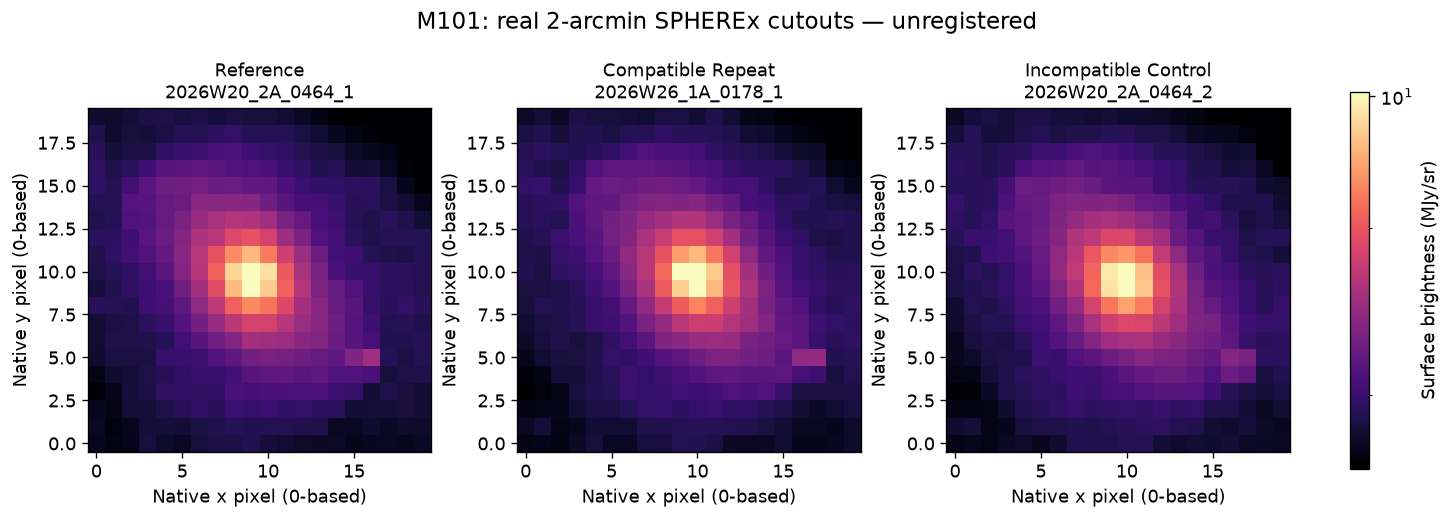

In [3]:
arrays = [fits.getdata(ROOT / asset['local_path'], 'IMAGE') for asset in manifest['cutouts']]
low, high = np.nanpercentile(np.concatenate([a.ravel() for a in arrays]), [2, 99.5])
norm = AsinhNorm(linear_width=max((high-low)/10, 0.001), vmin=low, vmax=high)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), layout='constrained')
for ax, role, data in zip(axes, roles, arrays):
    image = ax.imshow(data, origin='lower', interpolation='nearest', cmap='magma', norm=norm)
    ax.set_title(f"{role.replace('_', ' ').title()}\n{observations[role]['observation_id']}")
    ax.set_xlabel('Native x pixel (0-based)')
    ax.set_ylabel('Native y pixel (0-based)')
fig.colorbar(image, ax=axes, label='Surface brightness (MJy/sr)', shrink=0.8)
fig.suptitle('M101: real 2-arcmin SPHEREx cutouts — unregistered', fontsize=14)
fig.savefig(figures / 'native_cutouts.png', dpi=150)
plt.show()


### Local wavelength comparability
Different positions on the same linear-variable-filter detector can sample different wavelengths.
Below, each line is the target's center wavelength ± half its FWHM bandwidth. This interval
is a diagnostic proxy; it does not show the shape of the instrument transmission response.


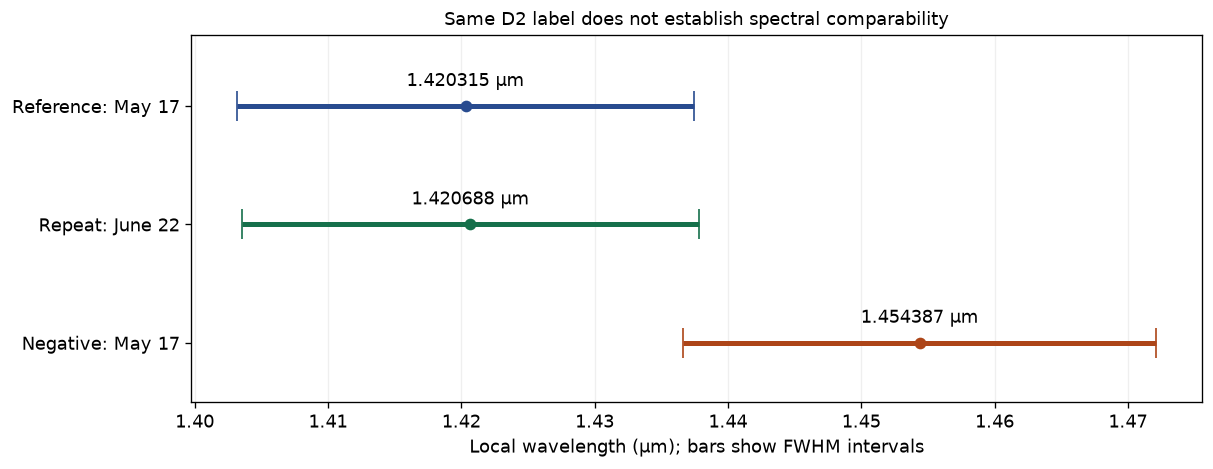

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
colors = ['#284b8f', '#15704b', '#ad4518']
for index, (role, color) in enumerate(zip(roles, colors)):
    item = observations[role]
    wave, width = item['wavelength_um'], item['bandwidth_um']
    ax.errorbar(wave, 2-index, xerr=width/2, fmt='o', color=color, capsize=9, linewidth=3)
    ax.annotate(f'{wave:.6f} µm', (wave, 2-index), xytext=(0, 12),
                textcoords='offset points', ha='center')
ax.set_yticks([2, 1, 0], ['Reference: May 17', 'Repeat: June 22', 'Negative: May 17'])
ax.set_ylim(-.5, 2.6)
ax.set_xlabel('Local wavelength (µm); bars show FWHM intervals')
ax.set_title('Same D2 label does not establish spectral comparability')
ax.grid(axis='x', alpha=.2)
fig.savefig(figures / 'local_wavelength_intervals.png', dpi=150)
plt.show()


### Gates and measured evidence

In [5]:
table(['Comparison', 'Δt (days)', 'Common usable', 'Min local interval proxy', 'Decision'], [
    [role.replace('_', ' '), f"{pair['epoch_separation_seconds']/86400:.6f}",
     f"{pair['geometry']['common_usable_pixels']}/400 ({pair['geometry']['common_usable_fraction']:.2%})",
     f"{pair['geometry']['minimum_local_interval_overlap']:.2%}",
     'Development GO' if pair['feasible_for_backend_development'] else ', '.join(pair['blocking_reasons'])]
    for role, pair in report['comparisons'].items()])
assert report['comparisons']['compatible_repeat']['feasible_for_backend_development']
assert not report['comparisons']['incompatible_control']['feasible_for_backend_development']
print('Both expected decisions reproduced; no motion detection was performed.')


Comparison,Δt (days),Common usable,Min local interval proxy,Decision
compatible repeat,36.394305,353/400 (88.25%),98.92%,Development GO
incompatible control,0.001492,316/400 (79.00%),1.93%,"common_coverage, local_wavelength_overlap, center_wavelength_shift"


Both expected decisions reproduced; no motion detection was performed.


## Takeaways
Proceed with the bounded observation-discovery vertical slice using the pinned QR2 pair for
development. Keep the negative exposure as a regression control for wavelength and coverage checks.
Before scientific candidate claims, validate registration/PSF matching, calibration compatibility,
response functions and thresholds with the ML researcher. Seek a suitable QR3/ePSF pair or integrate
the documented newer ePSF route; this run does not validate that path.

IRSA also supplies a [3I/ATLAS observation table](https://irsa.ipac.caltech.edu/data/SPHEREx/docs/comet3iatlas/).
Its 259 metadata rows were verified separately. It is a follow-up mover resource, not an accepted
positive fixture: some wavelengths have low SNR and the comet can be extended. DataLink URLs in
that table require resolution before FITS downloading.

The complete challenge brief, judging and submission rules still require organizer verification.
Research helpers do not enable the API endpoints, worker, model or scientific detection stages.
